# 02. Daily drift and bias against ERA5

## Purpose

Follow every test and its production counterparts day by day over the 56 lead days. Questions: does the cold start of the bare-ERA5 runs go away when the state is completed? Does the source of the filled fields matter? How do the atmosphere and land contrasts look once every state is complete? Biases are regional means of model − ERA5 (raw values for fields without an ERA5 reference). The shading is the 10-90% range of the 20 DA_COUPLED members of the same start, the size of chaotic member-to-member differences.

Issues found in the ERA5-initialized F20TR hindcasts (HYB_BASE, DA_LND) and tested here, all from the start of 16 Dec 2011:

1. **Incomplete ERA5 atmosphere.** `DART_INIT/ATM/v3.LR.ne30pg2.ERA5.eam.i.<date>.nc` holds only T, U, V, Q, PS, CLDLIQ and CLDICE, and EAM starts every missing field from zero. That includes the radiation's gases (`rad_climate` reads H2OLNZ, O3, N2OLNZ and CH4LNZ), the aerosols and the hydrometeor numbers. HYB_BASE and DA_LND therefore start radiatively dry and without ozone, about 6 K too cold over land.
2. **Which fields fill the gap.** The completed states take ERA5's T, U, V, Q, PS, CLDLIQ and CLDICE and everything else from either the DART ensemble mean (`ERA5_DARTFILL`, the HYB_BASE rebuild) or the free-running CLIM_BASE state (`ERA5_CLIMFILL`). `ensemble_perturbations/util/complete_era5_ic.py` does the completion. H2OLNZ follows the ERA5 Q.
3. **Atmosphere and land benefits with complete states.** The production DA_LND (bare ERA5 atmosphere) and DA_ATM (DATM land) mix the IC defect into the component contrasts. CLIMO_ATM and CLIMO_LND instead replace one component of DA_COUPLED EN40 with the complete CLIM_BASE state (Berner-style).

Every test is a single member, so a difference A − B is judged against `ev.noise_scale`: √2 × the member spread of the 20-member DA_COUPLED ensemble of the same start. Beyond the first days, a difference smaller than this cannot be told apart from the chaotic divergence of two members.

## Inputs and outputs

Model: `<root>/<case>_2011121600/<ENxx>/post/{atm,lnd}/180x360_aave/ts/{daily,6hourly}/0yr`, written by `post_process/regen_f20tr_ts.sh` for the production runs (`INPUT_DATA_ROOT`) and the tests (`TEST_DATA_ROOT`). Daily values per lead day, as in hind_lead_eval: 00Z-00Z means of the 6-hourly fields, and the 00Z state ending each day for the pressure levels. Reference: ERA5 1-degree (`ERA5/1x1/daily`, 00Z states from `ERA5/1x1/6hourly`); total ozone from ERA5 `TCO`.

Outputs: `data/era5_ic_test/drift/regional_<VAR>.nc` (run value and bias, ERA5, ensemble member biases, by region and lead), `comparison_windows.csv` (window means of A − B and their ratio to the noise scale); figures `figure/era5_ic_test/drift/drift_<GROUP>_<REGION>.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")            # production F20TR hindcasts
TEST_DATA_ROOT = Path("/pscratch/sd/z/zhan391/e3sm_dart/simulation")             # the test runs
IC_ROOT = Path("/global/cfs/cdirs/m4849/zhan391")                                  # initial-file library (DART_INIT/, e3sm_dart/)
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                     # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"
WORKFLOW_NAME = "era5_ic_test"

RUN_KEYS = ("ERA5_BARE", "ERA5_DARTFILL", "ERA5_CLIMFILL", "DA_COUPLED", "DA_ATM", "DA_LND", "CLIMO_ATM", "CLIMO_LND")
ENSEMBLE_RUN = "DA_COUPLED"        # its whole ensemble of the same start gives the shading and the noise scale
MAX_MEMBERS = None                 # e.g. 5 for a quick look
MAX_LEAD = 56
VARIABLES = ("TREFHT", "TS", "T850", "T100", "T050", "Z500", "TOZ", "FLDS", "FLDSC", "FSDS", "LHFLX", "SHFLX",
             "TMQ", "PRECT", "FLUT", "CLDTOT", "PSL")
REGIONS = ("GLOBAL", "LAND", "OCEAN", "NH_LAND", "TROPICS", "NH_POLAR", "SH_POLAR")
WINDOWS = {"days 1-3": (1, 3), "days 4-10": (4, 10), "days 11-28": (11, 28), "days 29-56": (29, 56)}
TOPIC = "drift"
FORCE_COMPUTE = False

# plotting
PLOT_GROUPS = ("era5_completion", "component_swap")
PLOT_REGIONS = ("LAND", "NH_LAND", "OCEAN", "GLOBAL")
PLOT_VARIABLES = ("TREFHT", "T850", "T050", "TOZ", "FLDS", "FLDSC", "FSDS", "LHFLX", "PRECT")
FIGURE_DPI = 200
SHOW = True

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
for p in (repo / "era5_ic_test", repo / "diagnostic"):     # ic_util (this directory), util (shared readers)
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from ic_util import ic_test_eval as ev
from ic_util.ic_test_runs import COMPARISONS, GROUPS, INIT, RUNS, check_runs, ensemble_members, member_dir
from util.hind_case_io import cached_dataset, cached_table, figure_saver

check_runs(RUN_KEYS)
ROOTS = {"test": TEST_DATA_ROOT, "production": INPUT_DATA_ROOT}
data_dir = DIAGNOSTIC_OUTPUT_ROOT / "data" / WORKFLOW_NAME / TOPIC
figure_dir = DIAGNOSTIC_OUTPUT_ROOT / "figure" / WORKFLOW_NAME / TOPIC
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
save = figure_saver(figure_dir, dpi=FIGURE_DPI, show=SHOW)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

runs = pd.DataFrame([dict(run=k, case=f"{r.case}_{INIT.astype(object):%Y%m%d}00", member=r.member, source=r.source,
                          atmosphere=r.atm_ic, land=r.lnd_ic) for k, r in RUNS.items() if k in RUN_KEYS]).set_index("run")
display(runs)
display(pd.DataFrame([dict(comparison=k, A=a, B=b, question=q) for k, (a, b, q) in COMPARISONS.items()]).set_index("comparison"))

ens_case = RUNS[ENSEMBLE_RUN].case
ens_members = ensemble_members(ens_case, INIT, ROOTS[RUNS[ENSEMBLE_RUN].source])[:MAX_MEMBERS]
print(f"[ENSEMBLE] {ENSEMBLE_RUN}: {len(ens_members)} members")
streams = {"atm_daily", "atm_6hourly"} | ({"lnd_daily"} if any(ev.spec(v).component == "lnd" for v in VARIABLES) else set())
paths = {k: member_dir(k, ROOTS) for k in RUN_KEYS}
not_ready = [f"{k}:{s}" for k, p in paths.items() for s in streams if not ev.stream_ok(p, s)]
not_ready += [f"{ENSEMBLE_RUN} {m}:{s}" for m in ens_members for s in streams
              if not ev.stream_ok(member_dir(ENSEMBLE_RUN, ROOTS).parent / m, s)]
if not_ready:
    raise RuntimeError(f"time series not regenerated (run post_process/regen_f20tr_ts.sh): {not_ready}")

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift


,case,member,source,atmosphere,land
run,,,,,
ERA5_BARE,F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_2011...,EN01,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DATM EN01
ERA5_DARTFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5COMPLETE_...,EN01,test,ERA5 + DART-mean fields,DATM EN01
ERA5_CLIMFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5CLIMFILL_...,EN01,test,ERA5 + CLIM_BASE fields,DATM EN01
DA_COUPLED,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_20...,EN40,production,DART EN40,DART EN40
DA_ATM,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_201112...,EN40,production,DART EN40,DATM EN40
DA_LND,F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_201112...,EN40,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DART EN40
CLIMO_ATM,F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIMO_ATM_TES...,EN40,test,CLIM_BASE + (DART EN40 - DART mean),DART EN40
CLIMO_LND,F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIMO_LND_TES...,EN40,test,DART EN40,CLIM_BASE (FREE_CLIM)


,A,B,question
comparison,,,
tracer_fix,ERA5_DARTFILL,ERA5_BARE,Does completing the ERA5 state remove the cold...
fill_source,ERA5_CLIMFILL,ERA5_DARTFILL,Does the source of the filled fields matter? (...
atm_clim,CLIMO_ATM,DA_COUPLED,"Atmosphere initial state, complete states: CLI..."
atm_bare_era5,DA_LND,DA_COUPLED,Atmosphere initial state as run in production ...
lnd_clim,CLIMO_LND,DA_COUPLED,Land initial state: CLIM_BASE - DART (both und...
lnd_datm,DA_ATM,DA_COUPLED,Land initial state as run in production DA_ATM...


[ENSEMBLE] DA_COUPLED: 20 members


## 4. Regional daily series

One file per variable: each run's regional mean and its bias against ERA5, ERA5 itself, and the bias of every member of the ensemble run. The file is reused while the runs, members, regions and lead range are unchanged.

In [4]:
grid_ref = ev.open_member(paths[RUN_KEYS[0]], INIT, "TREFHT", MAX_LEAD)
masks = ev.region_masks(REGIONS, grid_ref.lat, grid_ref.lon, LAND_SUPPORT_DIR).load()
stamp = "|".join([",".join(f"{k}={paths[k]}" for k in RUN_KEYS), ",".join(ens_members), ",".join(REGIONS), str(MAX_LEAD)])


def build_regional(v):
    ref = ev.open_era5(v, INIT, MAX_LEAD, OBSERVATION_ROOT)
    ref_r = None if ref is None else ev.regional_mean(ref, masks).load()
    def series(p):
        f = ev.open_member(p, INIT, v, MAX_LEAD)
        val = ev.regional_mean(f, masks).load()
        return val, (None if ref is None else ev.regional_mean(f - ref, masks).load())
    vals, biases = zip(*(series(paths[k]) for k in RUN_KEYS))
    ens = [series(member_dir(ENSEMBLE_RUN, ROOTS).parent / m) for m in ens_members]
    ds = xr.Dataset({"value": xr.concat(vals, pd.Index(list(RUN_KEYS), name="run")),
                     "ens_value": xr.concat([e[0] for e in ens], pd.Index(ens_members, name="member"))})
    if ref is not None:
        ds["bias"] = xr.concat(biases, pd.Index(list(RUN_KEYS), name="run"))
        ds["ens_bias"] = xr.concat([e[1] for e in ens], pd.Index(ens_members, name="member"))
        ds["era5"] = ref_r
    ds.attrs.update(variable=v, units=ev.spec(v).units, long_name=ev.spec(v).long_name, ensemble_run=ENSEMBLE_RUN,
                    reference="ERA5 " + ev.spec(v).era5 if ref is not None else "none")
    return ds.drop_vars([c for c in ("date",) if c in ds.coords])


regional = {}
for v in VARIABLES:
    regional[v] = cached_dataset(data_dir / f"regional_{v}.nc", lambda v=v: build_regional(v), stamp, force=FORCE_COMPUTE)

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_TREFHT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_TS.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_T850.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_T100.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_T050.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_Z500.nc


... (7 outputs left out)

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_PRECT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_FLUT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_CLDTOT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/regional_PSL.nc


## 5. Comparisons by lead window

For each comparison A − B (`COMPARISONS`): the window mean of the regional difference, and its ratio to the noise scale (√2 × the ensemble spread of the regional mean in that window). |ratio| > 2 marks a difference unlikely to come from member-to-member chaos alone (in days 1-3 the ensemble spread is still set by the initial perturbations, so the ratio is large for any IC difference).

In [5]:
def comparison_table():
    rows = []
    for v, ds in regional.items():
        val = ds["value"]
        noise = ev.window_means(ev.noise_scale(ds["ens_value"]), WINDOWS)
        for c, (a, b, _) in COMPARISONS.items():
            if a not in val.run or b not in val.run:
                continue
            d = ev.window_means(val.sel(run=a) - val.sel(run=b), WINDOWS)
            for r in ds.region.values:
                for w in WINDOWS:
                    x, n = float(d.sel(region=r, window=w)), float(noise.sel(region=r, window=w))
                    rows.append(dict(comparison=c, variable=v, units=ds.attrs["units"], region=r, window=w,
                                     difference=x, noise=n, ratio=x / n if n > 0 else np.nan))
    return pd.DataFrame(rows)


table = comparison_table()
table.to_csv(data_dir / "comparison_windows.csv", index=False)
print(f"[WRITE] {data_dir / 'comparison_windows.csv'}")
for region in ("LAND", "GLOBAL"):
    for var in ("TREFHT", "T850", "TOZ", "FLDS"):
        sel = table[(table.region == region) & (table.variable == var)]
        if len(sel):
            t = sel.pivot(index="comparison", columns="window", values="difference")[list(WINDOWS)]
            r = sel.pivot(index="comparison", columns="window", values="ratio")[list(WINDOWS)]
            print(f"\n{var} ({sel.units.iloc[0]}), {region}: A - B (ratio to noise)")
            display(t.round(2).astype(str) + " (" + r.round(1).astype(str) + ")")

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/era5_ic_test/drift/comparison_windows.csv

TREFHT (K), LAND: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
atm_bare_era5,-6.28 (-109.9),-6.43 (-29.4),-4.66 (-7.4),0.78 (0.9)
atm_clim,0.07 (1.2),0.06 (0.3),0.18 (0.3),0.39 (0.4)
fill_source,-0.02 (-0.3),-0.02 (-0.1),-0.05 (-0.1),-0.27 (-0.3)
lnd_clim,0.06 (1.1),0.0 (0.0),0.06 (0.1),0.8 (0.9)
lnd_datm,0.02 (0.4),-0.03 (-0.1),0.26 (0.4),0.99 (1.1)
tracer_fix,6.08 (106.4),6.14 (28.1),5.28 (8.4),-0.33 (-0.4)



T850 (K), LAND: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
atm_bare_era5,-1.96 (-28.9),-4.46 (-20.6),-3.17 (-6.3),0.77 (1.3)
atm_clim,-0.34 (-5.1),-0.3 (-1.4),-0.21 (-0.4),0.01 (0.0)
fill_source,0.02 (0.3),-0.04 (-0.2),-0.04 (-0.1),-0.23 (-0.4)
lnd_clim,-0.14 (-2.0),-0.16 (-0.7),-0.31 (-0.6),-0.14 (-0.2)
lnd_datm,-0.02 (-0.3),0.0 (0.0),-0.11 (-0.2),0.33 (0.6)
tracer_fix,1.84 (27.1),4.14 (19.0),3.38 (6.7),-0.83 (-1.4)



TOZ (DU), LAND: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
atm_bare_era5,-256.78 (-598.9),-218.19 (-272.8),-181.26 (-84.2),-152.29 (-41.0)
atm_clim,-15.96 (-37.2),-17.09 (-21.4),-15.16 (-7.0),-14.81 (-4.0)
fill_source,-15.53 (-36.2),-14.44 (-18.1),-13.63 (-6.3),-13.04 (-3.5)
lnd_clim,-0.01 (-0.0),0.18 (0.2),-0.41 (-0.2),-4.08 (-1.1)
lnd_datm,0.01 (0.0),0.14 (0.2),0.57 (0.3),-4.66 (-1.3)
tracer_fix,256.71 (598.7),219.66 (274.6),182.34 (84.7),150.22 (40.4)


... (6 outputs left out)


TOZ (DU), GLOBAL: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
atm_bare_era5,-239.99 (-1937.1),-192.88 (-1860.7),-151.15 (-664.4),-115.49 (-161.0)
atm_clim,-8.35 (-67.4),-8.69 (-83.9),-9.21 (-40.5),-9.85 (-13.7)
fill_source,-8.21 (-66.3),-8.39 (-81.0),-8.92 (-39.2),-9.93 (-13.8)
lnd_clim,-0.0 (-0.0),-0.03 (-0.3),-0.2 (-0.9),-0.52 (-0.7)
lnd_datm,0.01 (0.0),0.0 (0.0),-0.03 (-0.1),-0.51 (-0.7)
tracer_fix,239.64 (1934.3),192.56 (1857.7),151.06 (664.0),115.57 (161.1)



FLDS (W m-2), GLOBAL: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
atm_bare_era5,-97.08 (-302.3),-70.74 (-124.9),-58.57 (-54.8),-17.76 (-12.7)
atm_clim,5.63 (17.5),1.52 (2.7),0.21 (0.2),1.17 (0.8)
fill_source,0.13 (0.4),0.18 (0.3),0.22 (0.2),-0.74 (-0.5)
lnd_clim,0.13 (0.4),0.06 (0.1),-0.27 (-0.3),0.49 (0.3)
lnd_datm,0.05 (0.1),-0.01 (-0.0),0.3 (0.3),0.63 (0.5)
tracer_fix,95.7 (298.1),72.04 (127.2),58.6 (54.9),18.61 (13.3)


## 6. Figures: bias by lead day

One figure per run group and region, one panel per variable. Lines show each run's bias against ERA5 (or its raw value when there is no reference). Shading is the 10-90% range of the ensemble members, and the thin black line is the ensemble median.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_era5_completion_LAND.png


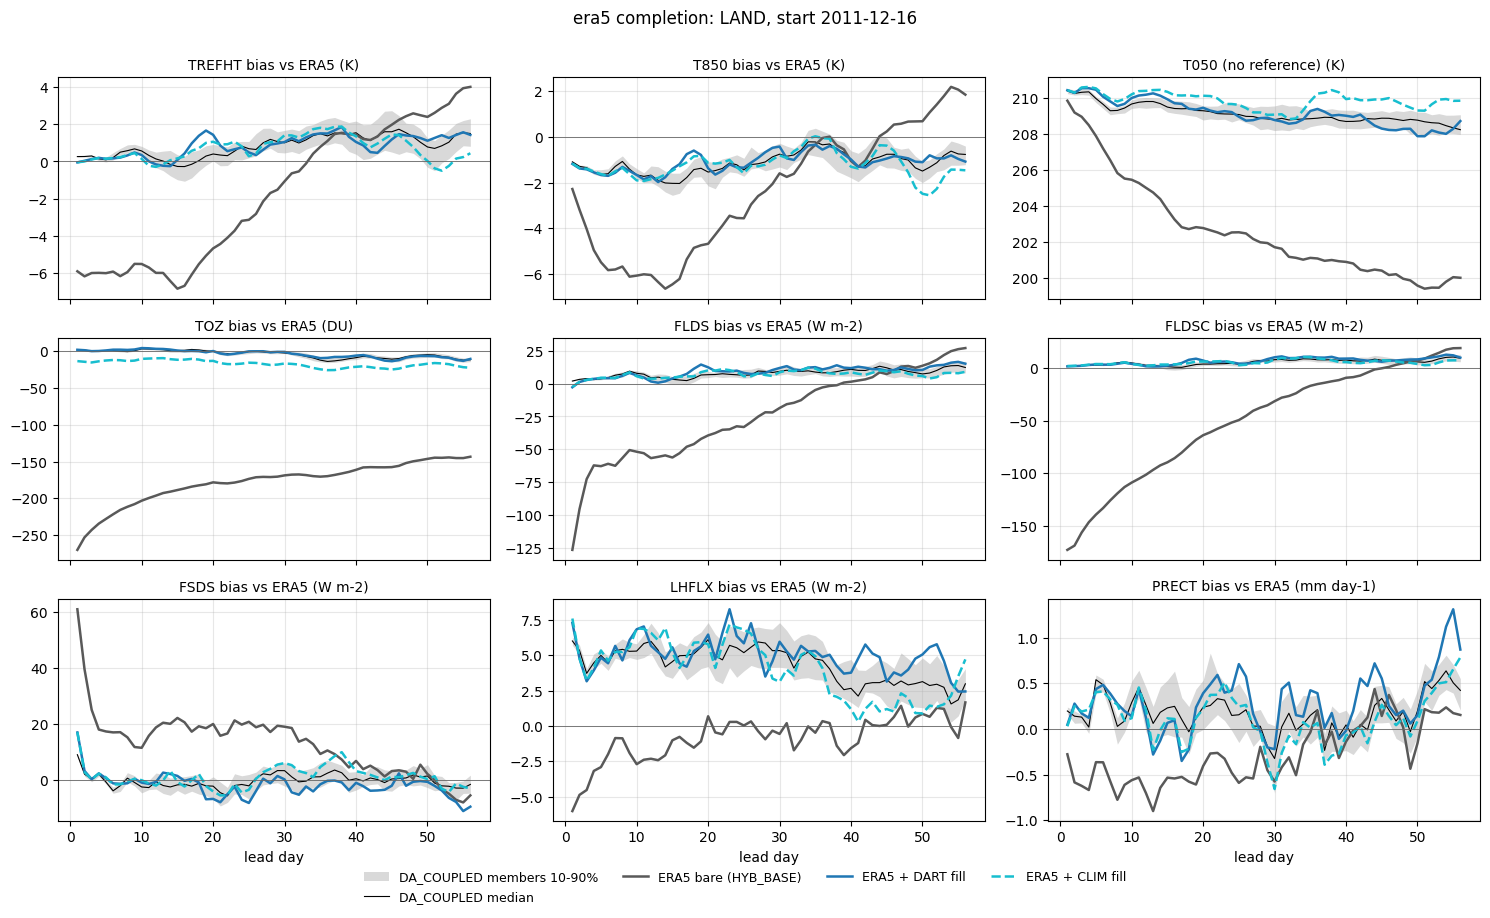

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_era5_completion_NH_LAND.png


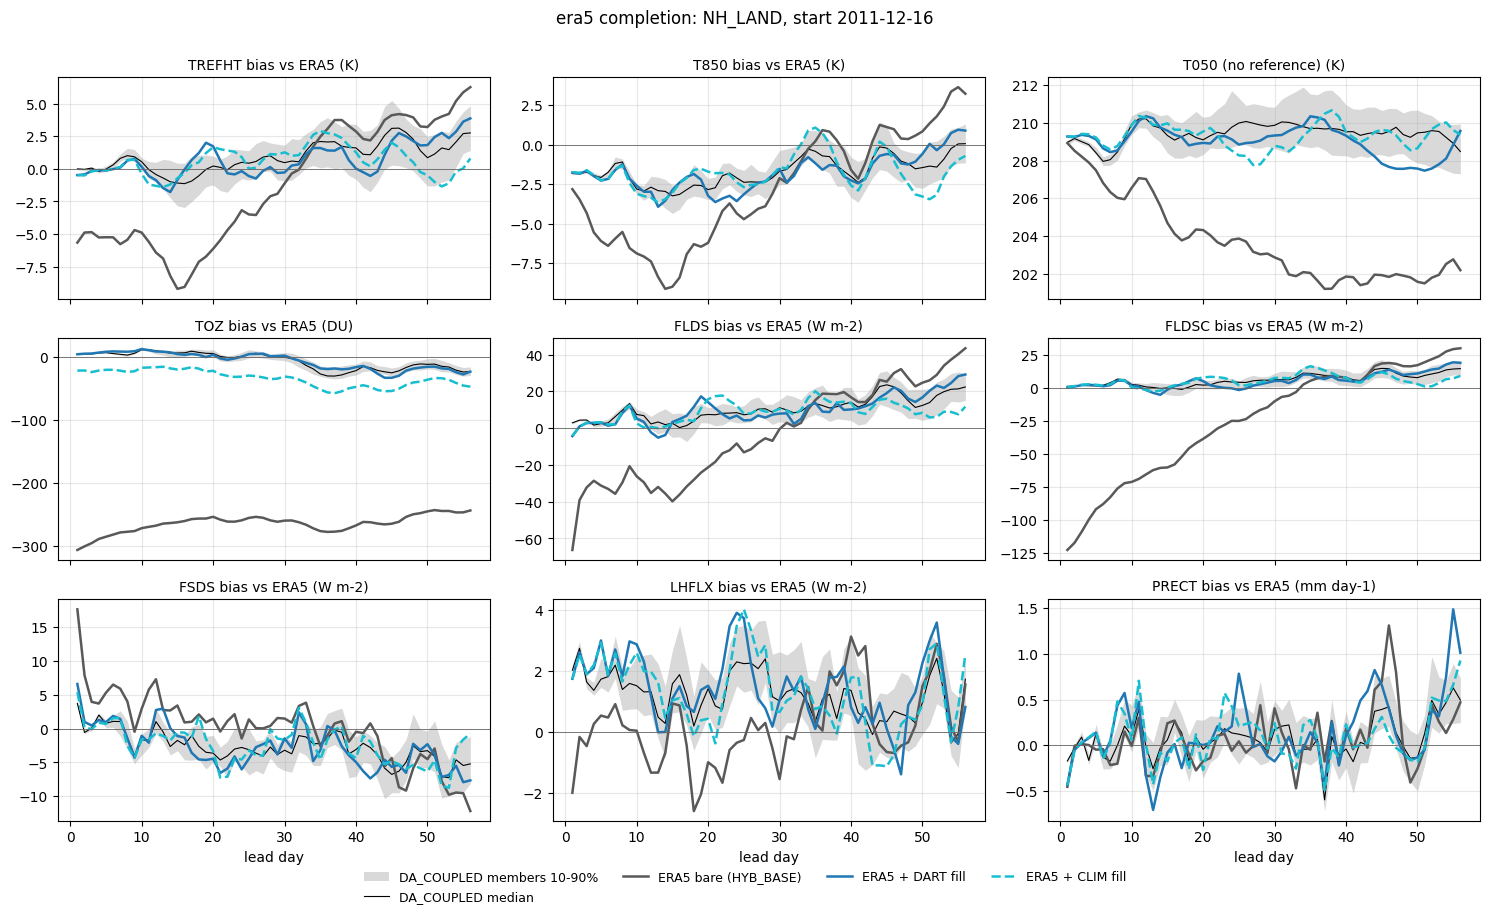

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_era5_completion_OCEAN.png


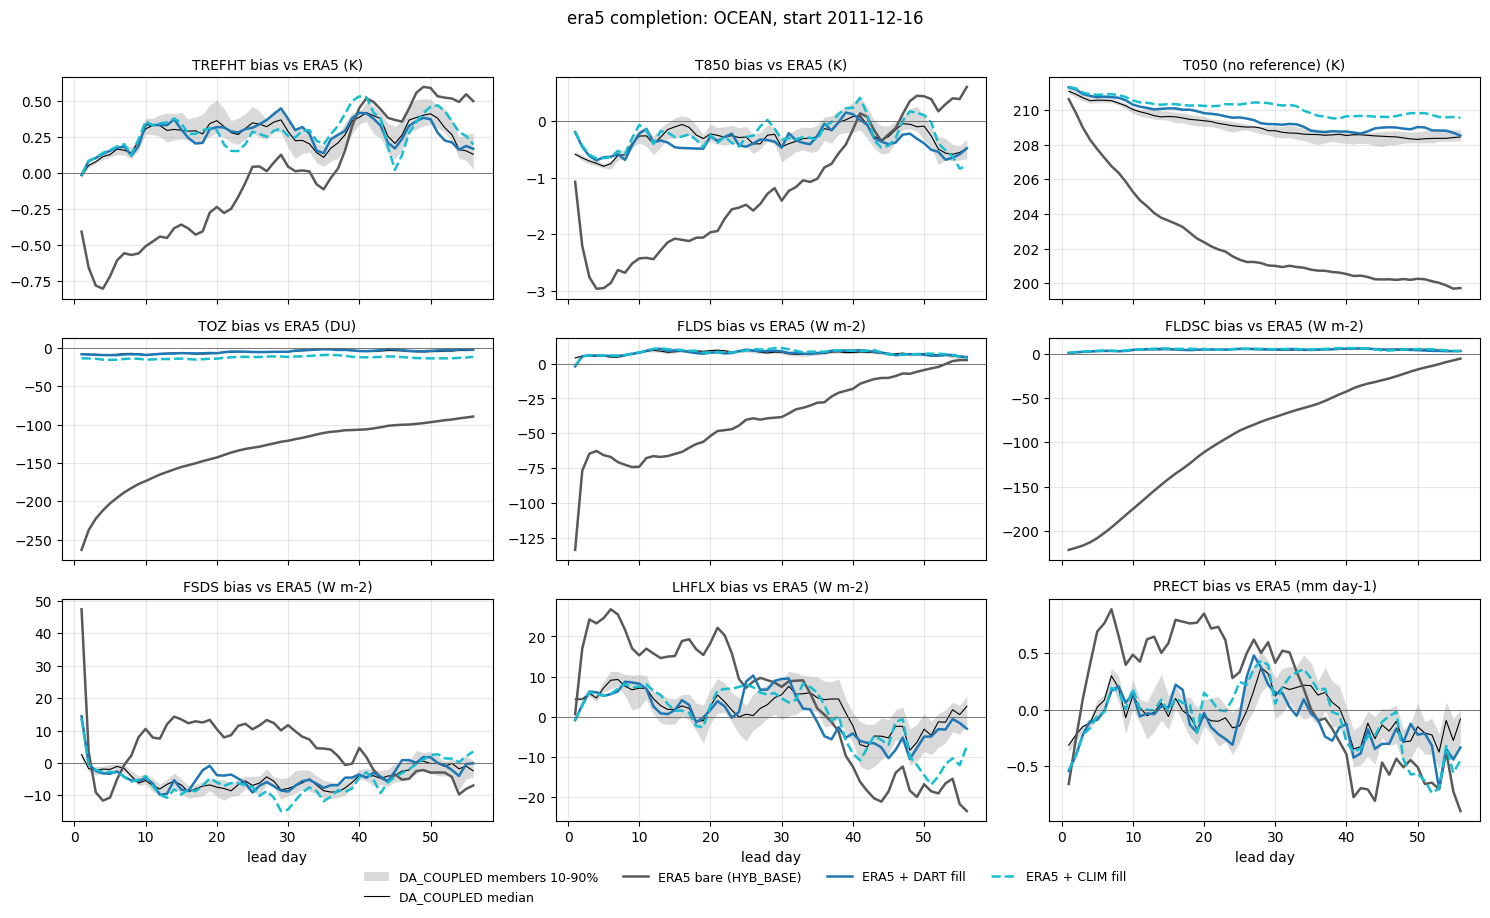

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_era5_completion_GLOBAL.png


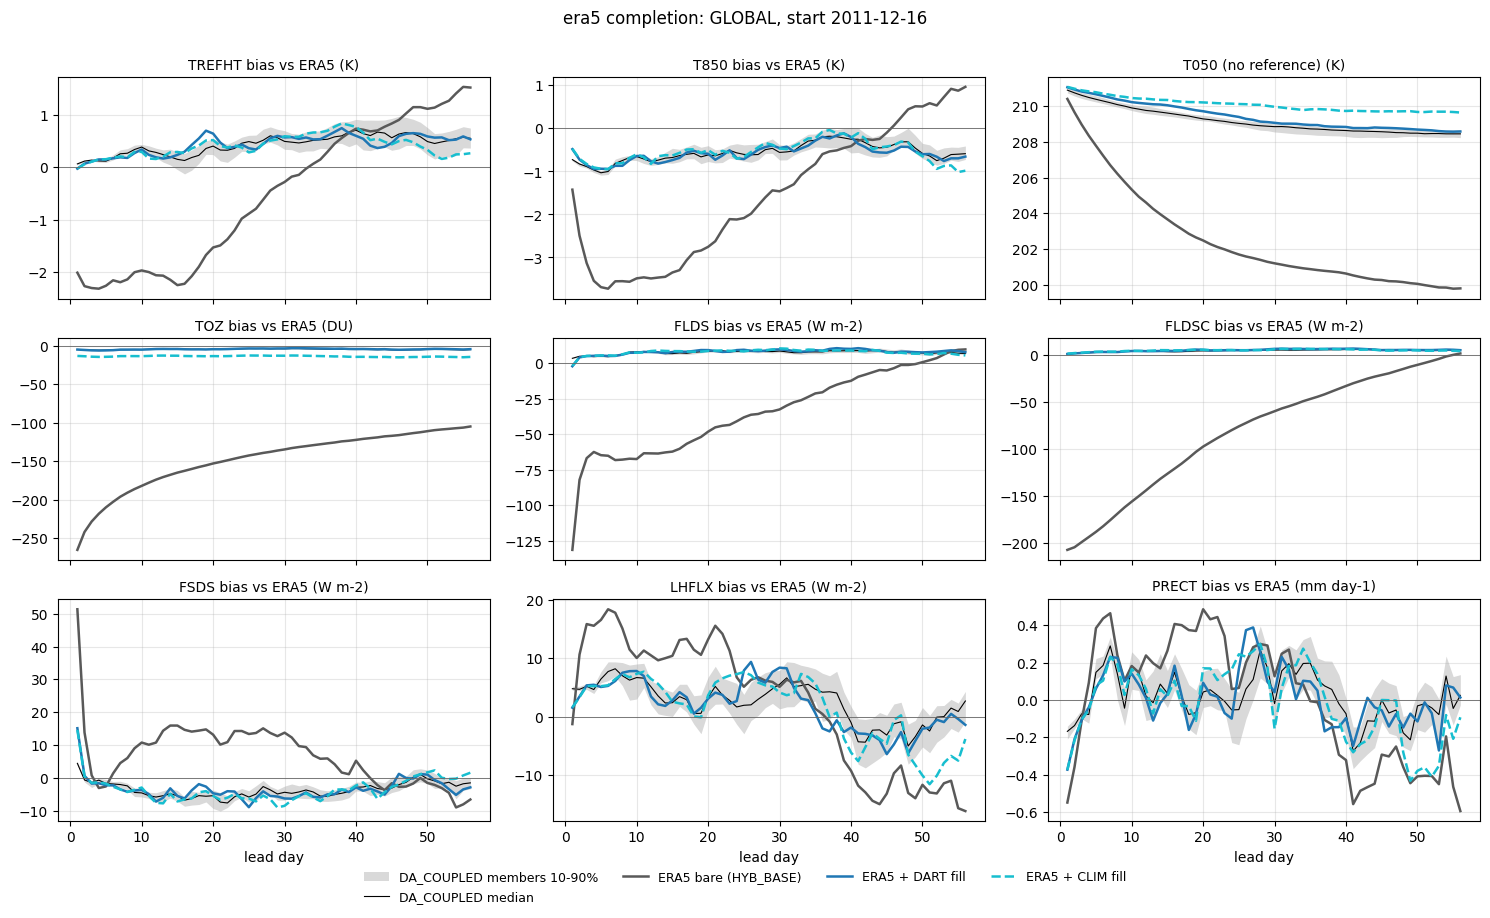

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_component_swap_LAND.png


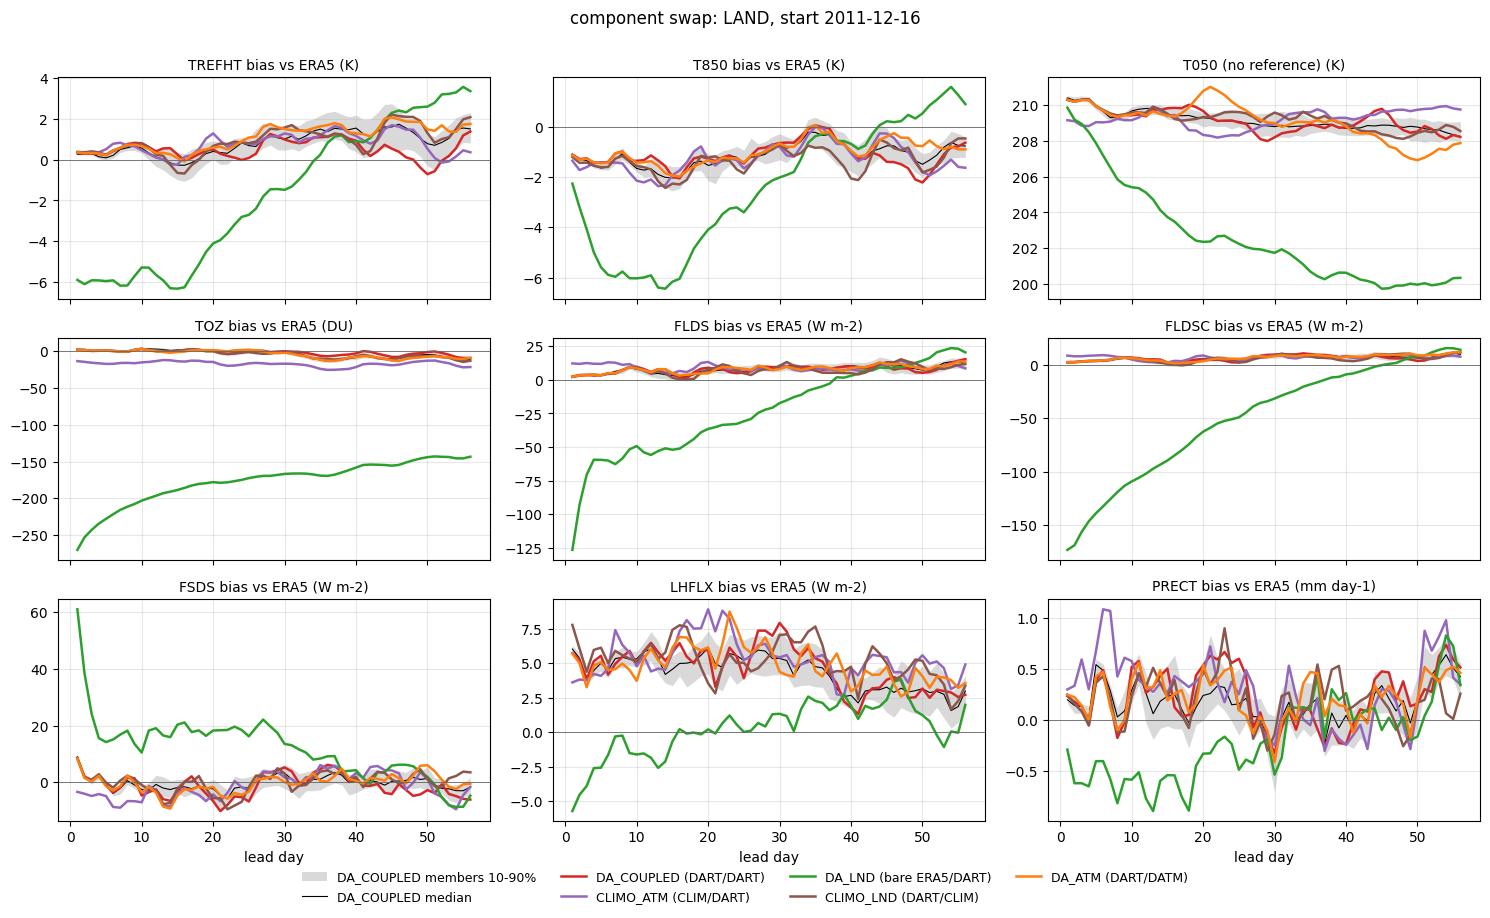

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_component_swap_NH_LAND.png


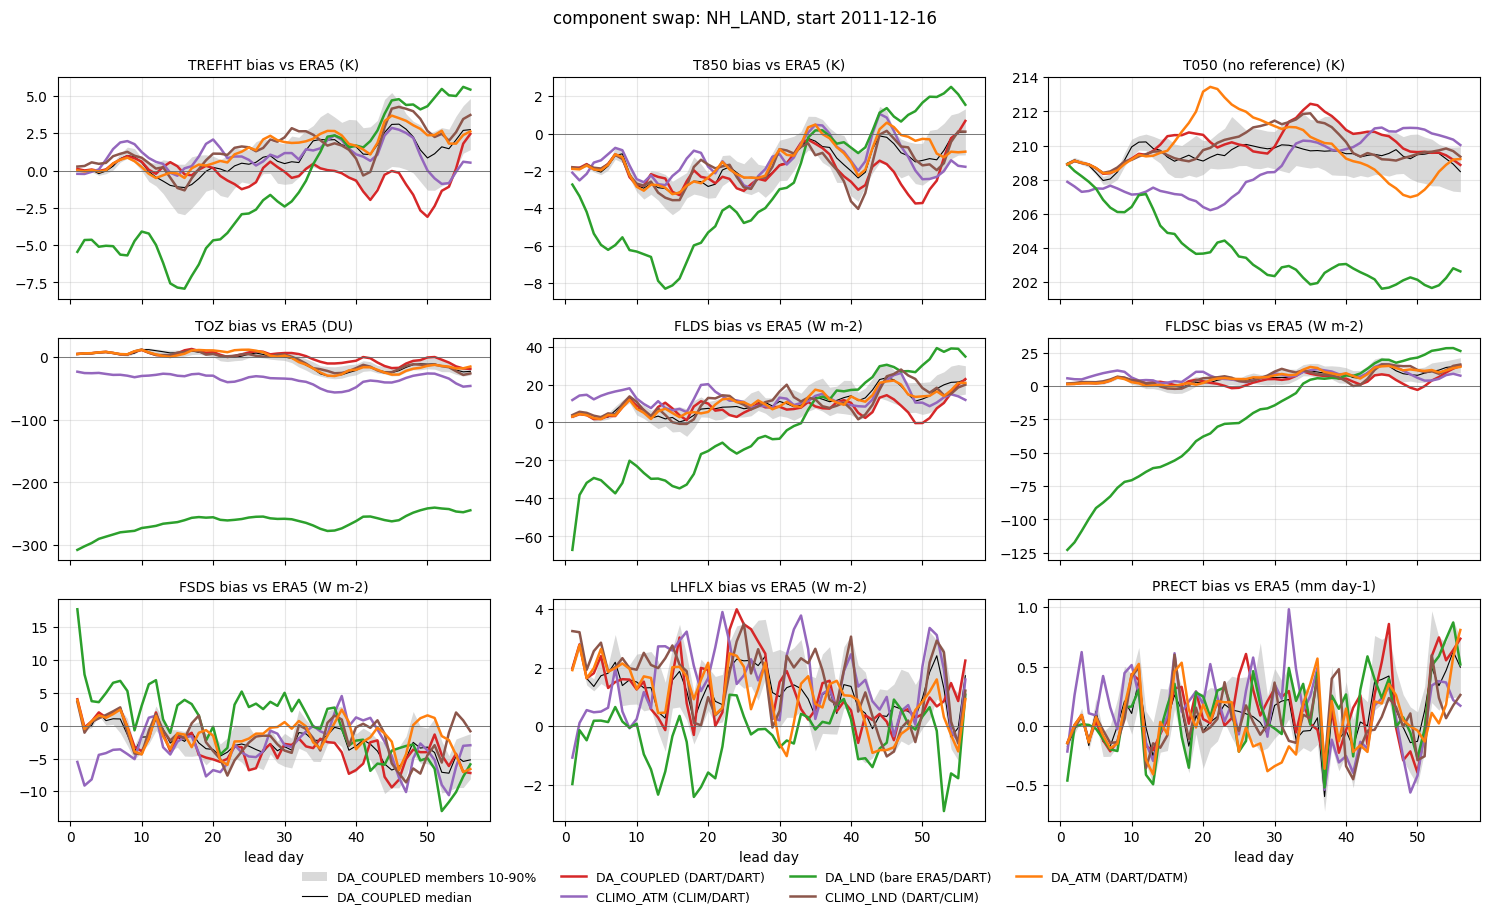

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_component_swap_OCEAN.png


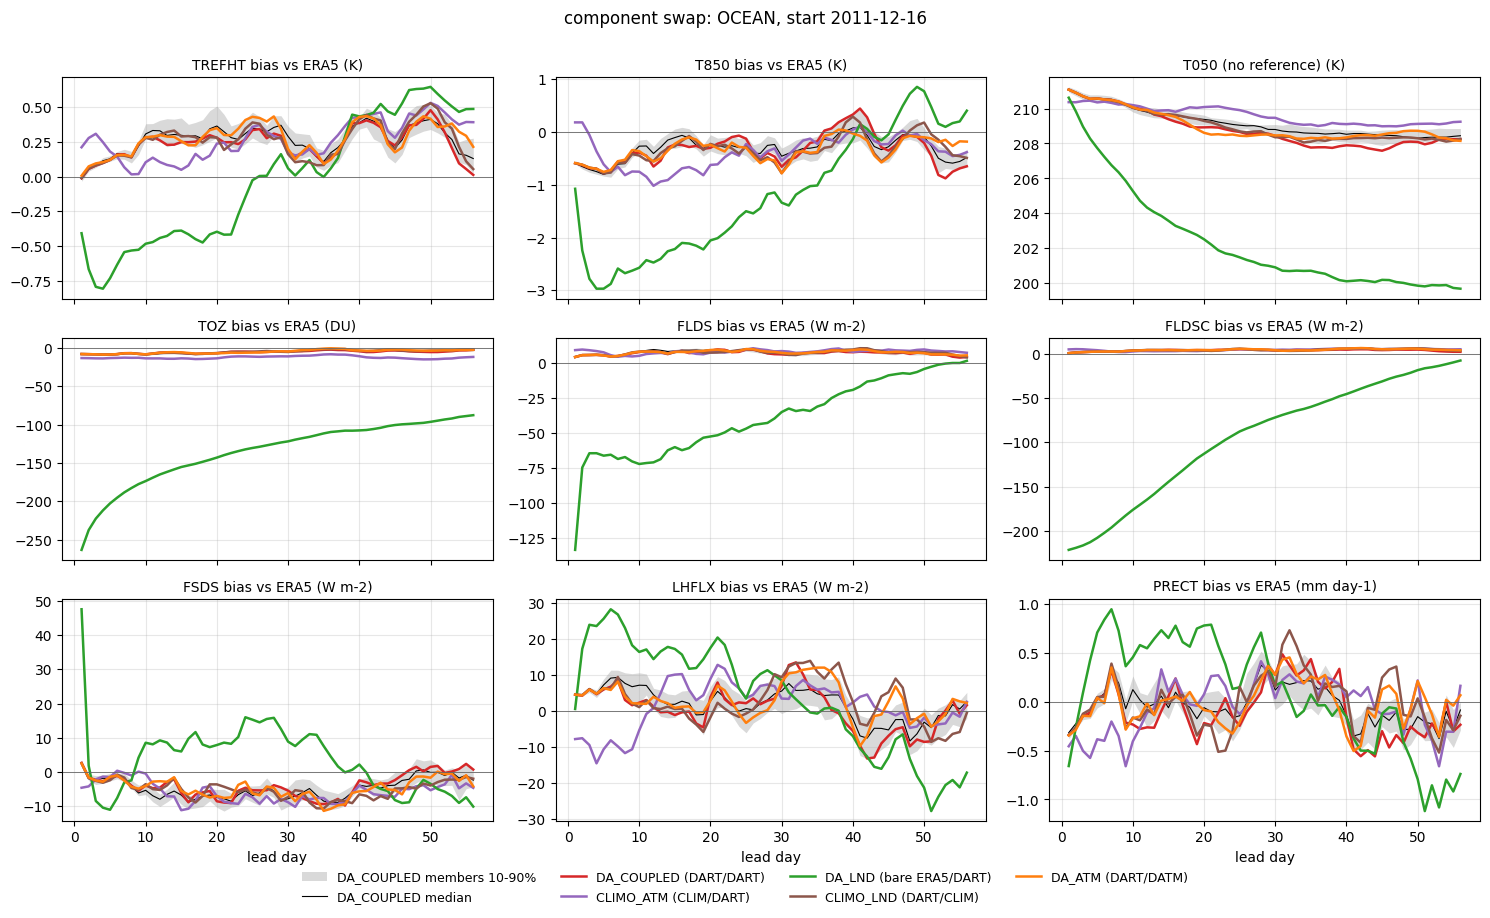

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/era5_ic_test/drift/drift_component_swap_GLOBAL.png


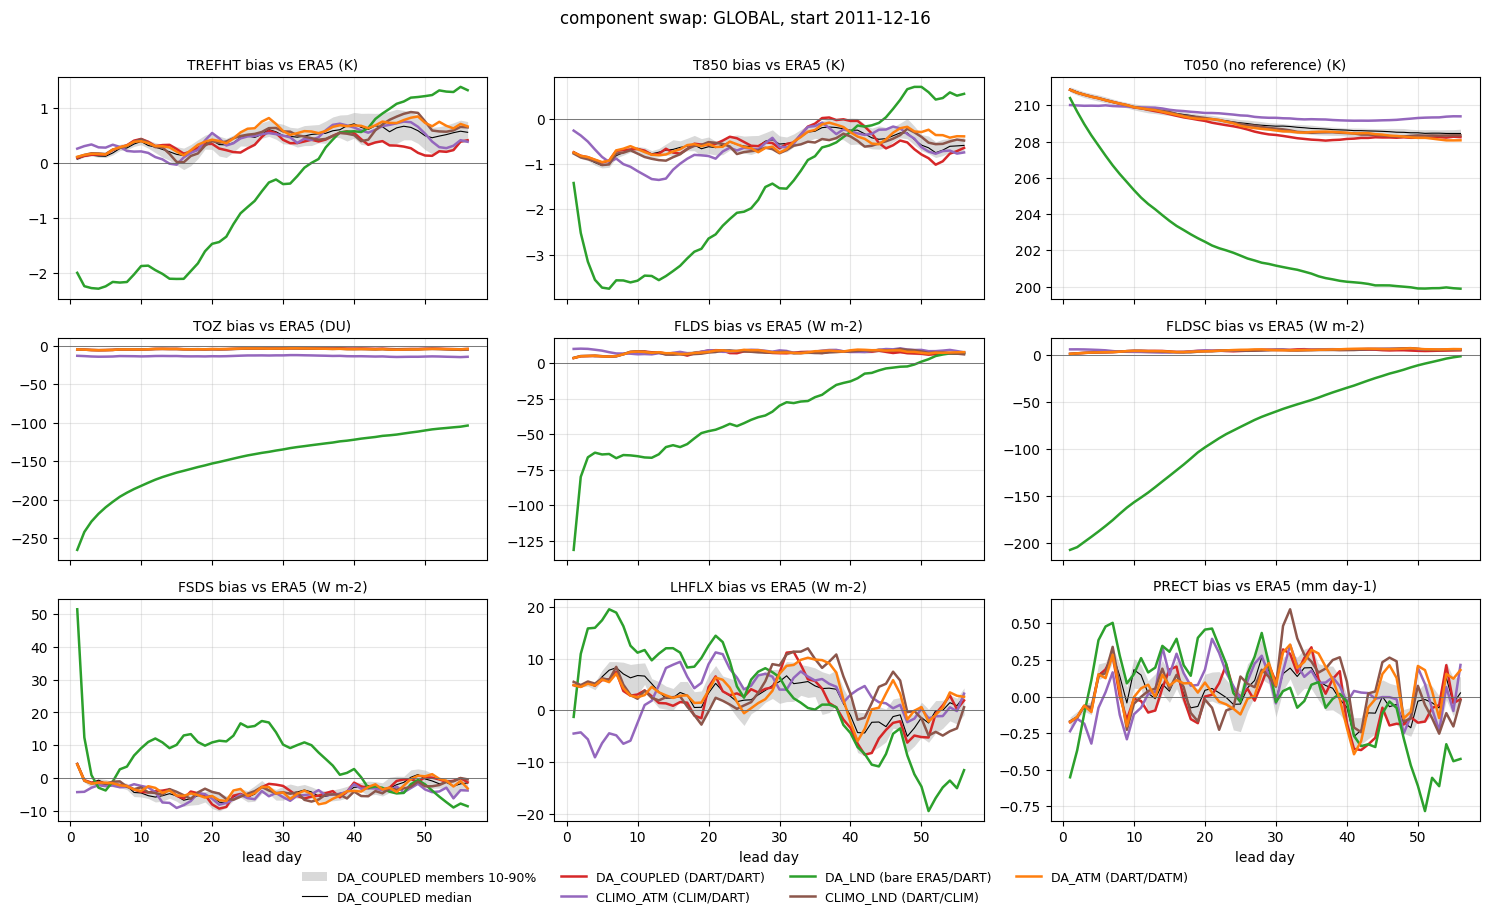

In [6]:
def plot_group(group, region):
    keys = [k for k in GROUPS[group] if k in RUN_KEYS]
    vs = [v for v in PLOT_VARIABLES if v in regional]
    ncol = 3
    nrow = int(np.ceil(len(vs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.0 * ncol, 2.9 * nrow), sharex=True, squeeze=False)
    for ax, v in zip(axes.flat, vs):
        ds = regional[v]
        has_ref = "bias" in ds
        y, ens = (ds["bias"], ds["ens_bias"]) if has_ref else (ds["value"], ds["ens_value"])
        e = ens.sel(region=region)
        ax.fill_between(e.lead, e.quantile(0.1, "member"), e.quantile(0.9, "member"), color="0.85", lw=0,
                        label=f"{ENSEMBLE_RUN} members 10-90%")
        ax.plot(e.lead, e.median("member"), color="k", lw=0.8, label=f"{ENSEMBLE_RUN} median")
        for k in keys:
            r = RUNS[k]
            ax.plot(y.lead, y.sel(run=k, region=region), color=r.color, ls=r.linestyle, lw=1.8, label=r.label)
        if has_ref:
            ax.axhline(0, color="0.4", lw=0.6)
        ax.set_title(f"{v} {'bias vs ERA5' if has_ref else '(no reference)'} ({ds.attrs['units']})", fontsize=10)
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("lead day")
    for ax in list(axes.flat)[len(vs):]:
        ax.axis("off")
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle(f"{group.replace('_', ' ')}: {region}, start {INIT}", y=1.0)
    fig.tight_layout()
    save(fig, f"drift_{group}_{region}.png")
    plt.show()


for g in PLOT_GROUPS:
    for r in PLOT_REGIONS:
        plot_group(g, r)